# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [24]:
import imblearn
print('imbalanced-learn:', imblearn.__version__)

imbalanced-learn: 0.14.2


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [26]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if X.ndim != 2 or y.shape != (len(X),):
            raise ValueError('Некорректные размеры X или y')
        if self.gd_type not in ('full', 'stochastic'):
            raise ValueError('Неизвестный тип градиентного спуска')
        X = np.column_stack((np.ones(len(X)), X))
        self.n_features_in_ = X.shape[1] - 1
        self.classes_ = np.array([0, 1])
        self.w = (np.zeros(X.shape[1]) if self.w0 is None
                  else np.asarray(self.w0, dtype=float).copy())
        if self.w.shape != (X.shape[1],):
            raise ValueError('Размер w0 должен быть d + 1')
        self.loss_history = []
        self.stopped_by_ = 'max_iter'
        self.n_iter_ = 0
        rng = np.random.default_rng(self.random_state)
        for iteration in range(self.max_iter):
            self.loss_history.append(self.calc_loss(X, y))
            if self.gd_type == 'stochastic':
                indices = rng.choice(len(X), size=min(self.batch_size, len(X)), replace=False)
                gradient = self.calc_gradient(X[indices], y[indices])
            else:
                gradient = self.calc_gradient(X, y)
            next_w = self.w - self.eta * gradient
            step = np.linalg.norm(next_w - self.w)
            self.w = next_w
            self.n_iter_ = iteration + 1
            if step < self.tolerance:
                self.stopped_by_ = 'tolerance'
                break
        return self

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def predict_proba(self, X):
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')
        X = np.asarray(X, dtype=float)
        p = self.sigmoid(np.column_stack((np.ones(len(X)), X)) @ self.w)
        return np.column_stack((1 - p, p))

    def predict(self, X, threshold=0.5):
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        return X.T @ (self.sigmoid(X @ self.w) - y) / len(y)

    def calc_loss(self, X, y):
        p = np.clip(self.sigmoid(X @ self.w), 1e-15, 1 - 1e-15)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [27]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 2.28e-10


Теперь проверим работу класса на синтетических данных.

In [28]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

GD: 1000 итераций, max_iter, loss=0.51245
SGD: 1000 итераций, max_iter, loss=0.51293


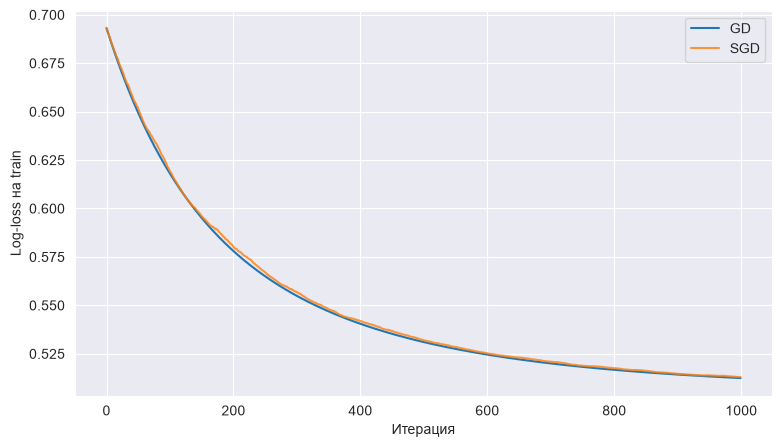

In [29]:
gd = LogReg(gd_type='full').fit(X_train, y_train)
sgd = LogReg(gd_type='stochastic').fit(X_train, y_train)
for name, model in [('GD', gd), ('SGD', sgd)]:
    print(f'{name}: {model.n_iter_} итераций, {model.stopped_by_}, loss={model.loss_history[-1]:.5f}')
plt.figure(figsize=(9, 5))
plt.plot(gd.loss_history, label='GD')
plt.plot(sgd.loss_history, label='SGD', alpha=.8)
plt.xlabel('Итерация'); plt.ylabel('Log-loss на train'); plt.legend(); plt.show()

**Вывод.** Оба метода остановились по `max_iter=1000`: loss полного GD ≈ 0.51245, SGD ≈ 0.51293. Полный метод использует все 14 000 объектов за шаг, стохастический — 32. Поэтому первая кривая гладкая, вторая шумит. При постоянном шаге батчи дают разные градиенты, и SGD трудно достичь маленькой нормы очередного обновления.

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

,eta,iterations,stop,loss
0,0.001,1000,max_iter,0.618141
1,0.010,1000,max_iter,0.512451
2,0.100,465,tolerance,0.505762
3,1.000,70,tolerance,0.505757
4,10.000,1000,max_iter,0.945807


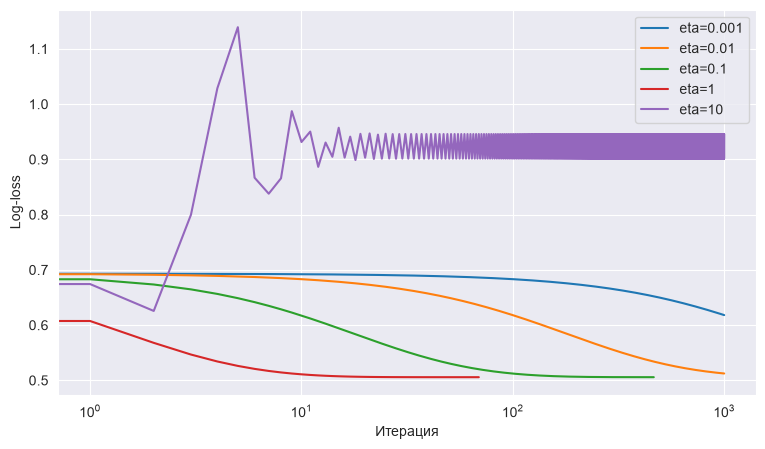

In [30]:
eta_models = {}
eta_results = []
plt.figure(figsize=(9, 5))
for eta in [1e-3, 1e-2, 1e-1, 1, 10]:
    model = LogReg(eta=eta).fit(X_train, y_train)
    eta_models[eta] = model
    eta_results.append([eta, model.n_iter_, model.stopped_by_, model.loss_history[-1]])
    plt.plot(model.loss_history, label=f'eta={eta:g}')
display(pd.DataFrame(eta_results, columns=['eta', 'iterations', 'stop', 'loss']))
plt.xscale('log'); plt.xlabel('Итерация'); plt.ylabel('Log-loss'); plt.legend(); plt.show()

**Вывод.** При `eta=0.001` спуск медленный (loss ≈ 0.618 после 1000 шагов). Шаги 0.1 и 1 сходятся к loss ≈ 0.50576 за 465 и 70 итераций. При `eta=10` спуск перескакивает минимум и за 1000 шагов остаётся около 0.946.

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [31]:
gd_compare = LogReg(eta=.1, tolerance=1e-6, max_iter=5000).fit(X_train, y_train)
sgd_compare = LogReg(gd_type='stochastic', max_iter=5000).fit(X_train, y_train)
sklearn_model = LogisticRegression(max_iter=5000).fit(X_train, y_train)
rows = []
for name, model in [('Свой GD', gd_compare), ('Свой SGD', sgd_compare), ('sklearn', sklearn_model)]:
    rows.append([name, metrics.accuracy_score(y_test, model.predict(X_test)),
                 metrics.roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])])
display(pd.DataFrame(rows, columns=['model', 'accuracy', 'ROC-AUC']).set_index('model'))
sklearn_weights = np.r_[sklearn_model.intercept_, sklearn_model.coef_.ravel()]
display(pd.DataFrame({'GD': gd_compare.w, 'sklearn': sklearn_weights,
                      'разница': gd_compare.w - sklearn_weights}))
no_penalty = LogisticRegression(C=np.inf, max_iter=5000).fit(X_train, y_train)
print('Максимальная разница без регуляризации:',
      np.max(np.abs(gd_compare.w - np.r_[no_penalty.intercept_, no_penalty.coef_.ravel()])))

,accuracy,ROC-AUC
model,,
Свой GD,0.776500,0.838674
Свой SGD,0.778833,0.838802
sklearn,0.776500,0.838676


,GD,sklearn,разница
0,-0.022149,-0.021880,-2.687749e-04
1,0.002763,0.002741,2.211539e-05
2,0.008962,0.009039,-7.708412e-05
3,-0.723200,-0.722690,-5.095888e-04
4,-0.262734,-0.262335,-3.993358e-04
5,0.016537,0.016588,-5.141336e-05
6,-0.011547,-0.011488,-5.983396e-05
7,0.005577,0.005587,-9.844983e-06
8,0.057235,0.057188,4.688525e-05
9,-0.001201,-0.001239,3.795723e-05


Максимальная разница без регуляризации: 0.00032333181776111886


**Вывод.** Метрики почти совпадают (accuracy ≈ 0.7765, ROC-AUC ≈ 0.8387). `sklearn` по умолчанию добавляет L2-регуляризацию, поэтому веса отличаются. При `C=np.inf` штраф отключён и максимальная разница с собственным GD составляет около 0.0003. SGD немного отличается из-за шумного градиента.

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [32]:
from pathlib import Path
data_path = Path('wine_quality.csv')
df = pd.read_csv(data_path if data_path.exists() else
                 'https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv')
print('Data shape:', df.shape)
df.head()

Data shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [33]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (4547, 12)  Test: (1950, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [34]:
print('Пропуски:'); display(df.isna().sum().to_frame('count'))
print('Полные дубликаты:', df.duplicated().sum())
print('Prevalence train/test:', y_train.mean(), y_test.mean())
constant_accuracy = metrics.accuracy_score(y_test, np.zeros(len(y_test)))
base_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(X_train, y_train)
print('Accuracy константы:', constant_accuracy)
print('Accuracy модели:', metrics.accuracy_score(y_test, base_model.predict(X_test)))

Пропуски:


,count
fixed_acidity,0
volatile_acidity,0
citric_acid,0
residual_sugar,0
chlorides,0
free_sulfur_dioxide,0
total_sulfur_dioxide,0
density,0
pH,0
sulphates,0


Полные дубликаты: 1177
Prevalence train/test: 0.19661315152848033 0.19641025641025642
Accuracy константы: 0.8035897435897436
Accuracy модели: 0.82


**Вывод.** Пропусков нет; полных дублей 1177. Без идентификатора образца нельзя уверенно считать одинаковые характеристики одним и тем же вином, поэтому строки не удаляем. `stratify=y` удерживает долю класса 1 около 19.6% в обеих выборках. Константа уже получает accuracy 0.8036 против 0.8200 у модели, но совсем не находит хорошие вина: accuracy скрывает эту проблему.

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TN=1501, FP=66, FN=285, TP=98


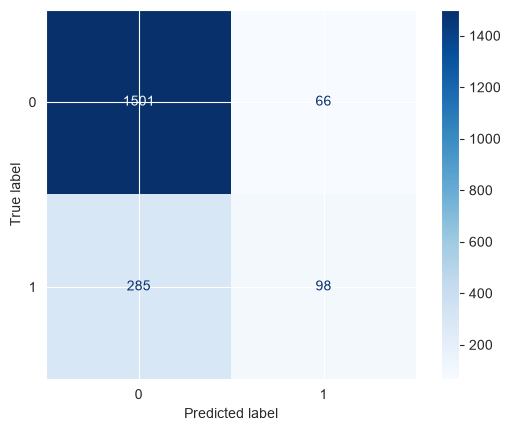

In [35]:
y_true = y_test.to_numpy()
y_pred = base_model.predict(X_test)
TP = int(((y_true == 1) & (y_pred == 1)).sum())
TN = int(((y_true == 0) & (y_pred == 0)).sum())
FP = int(((y_true == 0) & (y_pred == 1)).sum())
FN = int(((y_true == 1) & (y_pred == 0)).sum())
manual_cm = np.array([[TN, FP], [FN, TP]])
print(f'TN={TN}, FP={FP}, FN={FN}, TP={TP}')
assert np.array_equal(manual_cm, metrics.confusion_matrix(y_test, y_pred))
metrics.ConfusionMatrixDisplay(confusion_matrix=manual_cm).plot(cmap='Blues')
plt.show()

**Вывод.** FP — посредственное вино, рекомендованное клиенту; FN — хорошее вино, которое пропустили. FN значительно больше: 285 против 66 FP.

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [36]:
precision = TP / (TP + FP)
recall = TP / (TP + FN)
def f_beta(p, r, beta):
    return (1 + beta**2) * p * r / (beta**2 * p + r) if beta**2 * p + r else 0
manual = [precision, recall] + [f_beta(precision, recall, b) for b in [1, .5, 2]]
library = [metrics.precision_score(y_test, y_pred), metrics.recall_score(y_test, y_pred)] + [
    metrics.fbeta_score(y_test, y_pred, beta=b) for b in [1, .5, 2]]
display(pd.DataFrame({'вручную': manual, 'sklearn': library},
                     index=['precision', 'recall', 'F1', 'F0.5', 'F2']))
assert np.allclose(np.asarray(manual, dtype=float), np.asarray(library, dtype=float))

,вручную,sklearn
precision,0.597561,0.597561
recall,0.255875,0.255875
F1,0.358318,0.358318
F0.5,0.471607,0.471607
F2,0.288915,0.288915


**Вывод.** $F_{0.5}$ сильнее ценит precision: подходит, когда плохая рекомендация особенно неприятна. $F_2$ сильнее ценит recall: подходит для максимально широкой подборки. $F_1$ даёт равный компромисс.

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

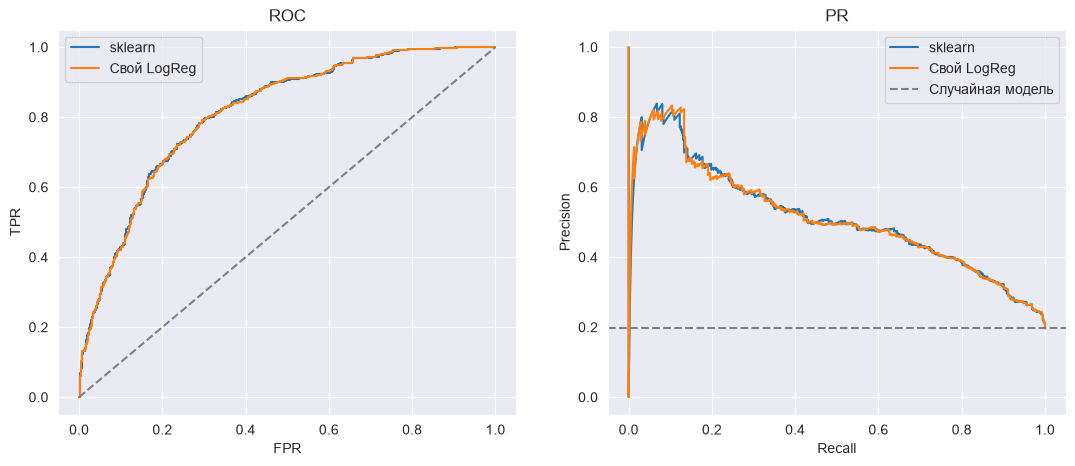

,ROC-AUC,PR-AUC
model,,
sklearn,0.813537,0.512104
Свой LogReg,0.813010,0.512286


,ROC-AUC
p,0.813537
10p,0.813537
p³,0.813537
logit(p),0.813537
-p,0.186463
метки,0.606878


In [37]:
wine_scaler = StandardScaler().fit(X_train)
X_wine_train = wine_scaler.transform(X_train)
X_wine_test = wine_scaler.transform(X_test)
own_wine = LogReg(eta=.1, tolerance=1e-6, max_iter=5000).fit(X_wine_train, y_train)
scores = {'sklearn': base_model.predict_proba(X_test)[:, 1],
          'Свой LogReg': own_wine.predict_proba(X_wine_test)[:, 1]}
ranking = []
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 5))
for name, s in scores.items():
    fpr, tpr, _ = metrics.roc_curve(y_test, s)
    p_curve, r_curve, _ = metrics.precision_recall_curve(y_test, s)
    ax_roc.plot(fpr, tpr, label=name)
    ax_pr.plot(r_curve, p_curve, label=name)
    ranking.append([name, metrics.roc_auc_score(y_test, s), metrics.average_precision_score(y_test, s)])
ax_roc.plot([0, 1], [0, 1], '--', color='grey')
ax_pr.axhline(y_test.mean(), linestyle='--', color='grey', label='Случайная модель')
ax_roc.set(xlabel='FPR', ylabel='TPR', title='ROC')
ax_pr.set(xlabel='Recall', ylabel='Precision', title='PR')
ax_roc.legend(); ax_pr.legend(); plt.show()
display(pd.DataFrame(ranking, columns=['model', 'ROC-AUC', 'PR-AUC']).set_index('model'))
p = scores['sklearn']
transformed = {'p': p, '10p': 10*p, 'p³': p**3,
               'logit(p)': np.log(np.clip(p, 1e-15, 1-1e-15) / (1-np.clip(p, 1e-15, 1-1e-15))),
               '-p': -p, 'метки': base_model.predict(X_test)}
display(pd.Series({name: metrics.roc_auc_score(y_test, values)
                   for name, values in transformed.items()}, name='ROC-AUC').to_frame())

**Вывод.** Собственная и библиотечная модели дают ROC-AUC около 0.813 и PR-AUC около 0.512, ранжирование почти одинаково. Базовый уровень PR-кривой случайной модели равен доле положительного класса 0.1964, а не 0.5. Строго возрастающие преобразования сохраняют ROC-AUC; `-p` обращает порядок и даёт 0.18646. Метки 0/1 теряют информацию о ранжировании: ROC-AUC падает до 0.60688.

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

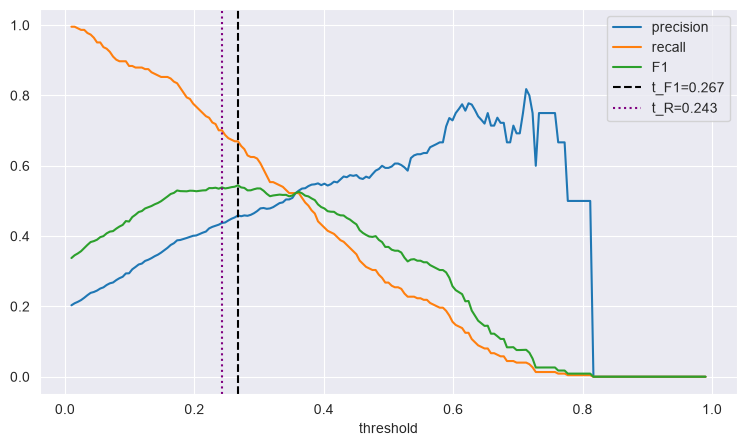

,t,precision,recall,F1
порог,,,,
0.5,0.500000,0.597561,0.255875,0.358318
t_F1,0.267374,0.469582,0.644909,0.543454
t_R,0.242626,0.436455,0.681462,0.532110


In [38]:
X_sub, X_val, y_sub, y_val = train_test_split(
    X_train, y_train, test_size=.25, stratify=y_train, random_state=RANDOM_STATE)
val_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(X_sub, y_sub)
val_p = val_model.predict_proba(X_val)[:, 1]
threshold_rows = []
for t in np.linspace(.01, .99, 199):
    pred = (val_p >= t).astype(int)
    threshold_rows.append([t, metrics.precision_score(y_val, pred, zero_division=0),
                           metrics.recall_score(y_val, pred), metrics.f1_score(y_val, pred)])
val_metrics = pd.DataFrame(threshold_rows, columns=['threshold', 'precision', 'recall', 'F1'])
t_f1 = float(val_metrics.loc[val_metrics.F1.idxmax(), 'threshold'])
candidates = val_metrics.query('recall >= 0.7')
t_recall = float(candidates.loc[candidates.precision == candidates.precision.max(), 'threshold'].max())
ax = val_metrics.plot(x='threshold', y=['precision', 'recall', 'F1'], figsize=(9, 5))
ax.axvline(t_f1, linestyle='--', color='black', label=f't_F1={t_f1:.3f}')
ax.axvline(t_recall, linestyle=':', color='purple', label=f't_R={t_recall:.3f}')
ax.legend(); plt.show()
base_model.fit(X_train, y_train)
test_p = base_model.predict_proba(X_test)[:, 1]
test_threshold_rows = []
for name, t in [('0.5', .5), ('t_F1', t_f1), ('t_R', t_recall)]:
    pred = (test_p >= t).astype(int)
    test_threshold_rows.append([name, t, metrics.precision_score(y_test, pred),
                                metrics.recall_score(y_test, pred), metrics.f1_score(y_test, pred)])
display(pd.DataFrame(test_threshold_rows,
    columns=['порог', 't', 'precision', 'recall', 'F1']).set_index('порог'))

**Вывод.** На validation выбраны $t_{F_1}\approx0.267$ и $t_R\approx0.243$. На test второй дал precision 0.4365 и recall 0.6815: требование 0.7 не выполнилось. Порог выбирался на другой выборке, поэтому гарантий на новых объектах нет. Для сценария предпочтителен $t_R$: он явно учитывает требование к полноте и среди допустимых порогов на validation максимизирует точность. Перед применением следует заложить запас по полноте.

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [39]:
def evaluate(model, X_eval=X_test, y_eval=y_test, threshold=.5):
    probability = model.predict_proba(X_eval)[:, 1]
    prediction = (probability >= threshold).astype(int)
    return dict(accuracy=metrics.accuracy_score(y_eval, prediction),
                precision=metrics.precision_score(y_eval, prediction, zero_division=0),
                recall=metrics.recall_score(y_eval, prediction),
                F1=metrics.f1_score(y_eval, prediction),
                ROC_AUC=metrics.roc_auc_score(y_eval, probability),
                PR_AUC=metrics.average_precision_score(y_eval, probability))
unweighted = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(X_train, y_train)
balanced = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=5000)).fit(X_train, y_train)
model_results = {'Без весов': evaluate(unweighted), 'balanced': evaluate(balanced)}
display(pd.DataFrame(model_results).T)
counts = y_train.value_counts().sort_index()
display((len(y_train) / (2 * counts)).rename('вес класса').to_frame())

,accuracy,precision,recall,F1,ROC_AUC,PR_AUC
Без весов,0.820000,0.597561,0.255875,0.358318,0.813537,0.512104
balanced,0.726667,0.396978,0.754569,0.520252,0.811339,0.500532


,вес класса
target,
0,0.622365
1,2.543065


**Вывод.** По формуле $n/(2n_k)$ веса равны 0.6224 для класса 0 и 2.5431 для класса 1. Recall вырос с 0.2559 до 0.7546, а precision снизился с 0.5976 до 0.3970. Accuracy тоже снизилась; ROC-AUC и PR-AUC изменились слабо, потому что главным образом изменилась рабочая точка при пороге 0.5.

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [40]:
from sklearn.base import clone
from imblearn.pipeline import make_pipeline as make_imblearn_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

samplers = {'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
            'NearMiss v2': NearMiss(version=2),
            'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
            'SMOTE': SMOTE(random_state=RANDOM_STATE)}
resampling_models = {}
resampled_counts = {}
scaled_train = StandardScaler().fit_transform(X_train)
for name, sampler in samplers.items():
    model = make_imblearn_pipeline(StandardScaler(), clone(sampler),
                                   LogisticRegression(max_iter=5000)).fit(X_train, y_train)
    resampling_models[name] = model
    model_results[name] = evaluate(model)
    _, resampled_y = clone(sampler).fit_resample(scaled_train, y_train)
    resampled_counts[name] = pd.Series(resampled_y).value_counts().sort_index()
display(pd.DataFrame(resampled_counts).T.rename(columns={0:'класс 0', 1:'класс 1'}))
display(pd.DataFrame(model_results).T)
smote_first = make_imblearn_pipeline(SMOTE(random_state=RANDOM_STATE), StandardScaler(),
                                     LogisticRegression(max_iter=5000)).fit(X_train, y_train)
display(pd.DataFrame({'scale → SMOTE': evaluate(resampling_models['SMOTE']),
                      'SMOTE → scale': evaluate(smote_first)}).T)

target,класс 0,класс 1
RandomUnderSampler,894,894
NearMiss v2,894,894
RandomOverSampler,3653,3653
SMOTE,3653,3653


,accuracy,precision,recall,F1,ROC_AUC,PR_AUC
Без весов,0.820000,0.597561,0.255875,0.358318,0.813537,0.512104
balanced,0.726667,0.396978,0.754569,0.520252,0.811339,0.500532
RandomUnderSampler,0.729744,0.401099,0.762402,0.525653,0.809354,0.500779
NearMiss v2,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
RandomOverSampler,0.726667,0.397260,0.757180,0.521114,0.811484,0.500216
SMOTE,0.729231,0.399166,0.749347,0.520871,0.812465,0.503980


,accuracy,precision,recall,F1,ROC_AUC,PR_AUC
scale → SMOTE,0.729231,0.399166,0.749347,0.520871,0.812465,0.503980
SMOTE → scale,0.733846,0.404225,0.749347,0.525160,0.811607,0.508942


**Вывод.** `imblearn` допускает `fit_resample` внутри пайплайна; при `predict` тестовые объекты не ресемплируются. Балансировка до разделения данных вызвала бы утечку повторов и синтетических соседей в test. Для `NearMiss` и `SMOTE` масштабирование перед ресемплингом важно из-за расстояний, для случайных методов порядок выбора объектов почти не меняется. Среди четырёх методов лучший PR-AUC у SMOTE (≈ 0.504), худший у NearMiss (≈ 0.400): последний удаляет много реальных объектов класса 0. Перестановка шагов для SMOTE изменила PR-AUC с 0.5040 до 0.5089.

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

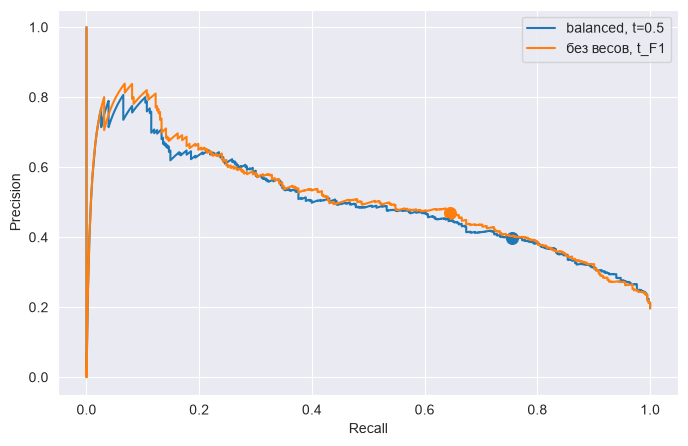

,precision,recall
модель,,
"balanced, t=0.5",0.396978,0.754569
"без весов, t_F1",0.469582,0.644909


In [41]:
curve_data = [('balanced, t=0.5', balanced, .5), ('без весов, t_F1', unweighted, t_f1)]
plt.figure(figsize=(8, 5))
points = []
for name, model, t in curve_data:
    p = model.predict_proba(X_test)[:, 1]
    precision_curve, recall_curve, _ = metrics.precision_recall_curve(y_test, p)
    line, = plt.plot(recall_curve, precision_curve, label=name)
    pred = (p >= t).astype(int)
    point = [metrics.precision_score(y_test, pred), metrics.recall_score(y_test, pred)]
    points.append([name, *point])
    plt.scatter(point[1], point[0], color=line.get_color(), s=70)
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.legend(); plt.show()
display(pd.DataFrame(points, columns=['модель', 'precision', 'recall']).set_index('модель'))

**Вывод.** PR-кривые близки: веса во многом действуют как снижение порога. При выбранных точках взвешенная модель дала precision 0.3970 и recall 0.7546, невзвешенная при $t_{F_1}$ — 0.4696 и 0.6449. Полной эквивалентности нет: веса меняют коэффициенты и немного меняют ранжирование.

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [42]:
def own_wine_metrics():
    pred = (scores['Свой LogReg'] >= .5).astype(int)
    return dict(accuracy=metrics.accuracy_score(y_test, pred),
                precision=metrics.precision_score(y_test, pred),
                recall=metrics.recall_score(y_test, pred),
                F1=metrics.f1_score(y_test, pred),
                ROC_AUC=metrics.roc_auc_score(y_test, scores['Свой LogReg']),
                PR_AUC=metrics.average_precision_score(y_test, scores['Свой LogReg']))
all_results = {'Свой LogReg, t=0.5': own_wine_metrics(),
               'sklearn, t=0.5': evaluate(unweighted),
               f'sklearn, t_F1={t_f1:.3f}': evaluate(unweighted, threshold=t_f1),
               f'sklearn, t_R={t_recall:.3f}': evaluate(unweighted, threshold=t_recall),
               **model_results}
display(pd.DataFrame(all_results).T.sort_values('PR_AUC', ascending=False))

,accuracy,precision,recall,F1,ROC_AUC,PR_AUC
"Свой LogReg, t=0.5",0.820513,0.602484,0.253264,0.356618,0.813010,0.512286
"sklearn, t=0.5",0.820000,0.597561,0.255875,0.358318,0.813537,0.512104
"sklearn, t_F1=0.267",0.787179,0.469582,0.644909,0.543454,0.813537,0.512104
"sklearn, t_R=0.243",0.764615,0.436455,0.681462,0.532110,0.813537,0.512104
Без весов,0.820000,0.597561,0.255875,0.358318,0.813537,0.512104
SMOTE,0.729231,0.399166,0.749347,0.520871,0.812465,0.503980
RandomUnderSampler,0.729744,0.401099,0.762402,0.525653,0.809354,0.500779
balanced,0.726667,0.396978,0.754569,0.520252,0.811339,0.500532
RandomOverSampler,0.726667,0.397260,0.757180,0.521114,0.811484,0.500216
NearMiss v2,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108


**Вывод.** Выбираю обычный пайплайн `StandardScaler` + `LogisticRegression` с порогом $t_R\approx0.243$, найденным на validation. На test он даёт precision 0.4365, recall 0.6815, $F_1=0.5321$: полнота выше стандартного порога, а точность выше, чем у большинства методов балансировки при пороге 0.5. Цель recall 0.7 на test немного не достигнута, поэтому перед применением порог нужно перепроверить на новых данных.

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [43]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)

final_model = unweighted
final_threshold = t_recall

joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(json.dumps({'threshold': float(final_threshold)}))
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)

## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷